# Model search: where each number comes from

Each cell prints numbers of `reports/MODEL_SEARCH.md` from the file they come from,
with the source path, the script that wrote it and the last commit of that file.
Nothing is retrained. Val split only: the search never reads the test rows (section 2). The one test score, taken afterwards, is in `test_team_summary.csv` (`src/42_test_score.py`).
Built and run by `src/41_trace_notebook.py`.

In [1]:
import hashlib, re, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from common import DATA_DIR
from score import TEAM, TARGETS, cols, load, score_table

T = ROOT / "reports" / "tables"
pd.set_option("display.width", 100)
pd.set_option("display.max_columns", 12)


def commit(path):
    out = subprocess.run(["git", "log", "-1", "--format=%h %ad", "--date=short",
                          "--", str(path)], cwd=ROOT, capture_output=True, text=True)
    return out.stdout.strip() or "uncommitted"


def src(path, script):
    p = Path(path)
    rel = p.relative_to(ROOT) if p.is_absolute() and ROOT in p.parents else p
    print(f"  source: {rel}")
    print(f"  script: {script}")
    print(f"  commit: {commit(path)}")


runs = pd.read_csv(T / "model_search_runs.csv")
summ = pd.read_csv(T / "model_search_summary.csv")
print("repo HEAD:", commit(ROOT))
print("runs:", len(runs), " configurations:", runs.name.nunique())
src(T / "model_search_runs.csv", "src/37_model_search.py")

repo HEAD: f80e4d6 2026-11-12
runs: 68  configurations: 24
  source: reports/tables/model_search_runs.csv
  script: src/37_model_search.py
  commit: d37142a 2026-11-12


## 1. Data file: SHA-1

In [2]:
expected = "263bb791129bccf2073b1c4e827acf82eafeb96e"
h = hashlib.sha1()
with open(TEAM.path, "rb") as f:  # bytes only; no rows are decoded
    for block in iter(lambda: f.read(1 << 20), b""):
        h.update(block)
print("file:     $TEAM_TABLE =", TEAM.path.name)
print("sha1:    ", h.hexdigest())
print("expected:", expected)
assert h.hexdigest() == expected

file:     $TEAM_TABLE = training_table.parquet
sha1:     263bb791129bccf2073b1c4e827acf82eafeb96e
expected: 263bb791129bccf2073b1c4e827acf82eafeb96e


## 2. The search never reads the test split

(a) every `load(` call in the search scripts asks for train and val only;
(b) `score.load` filters the split inside the parquet read and checks the split rule;
(c) loading what the scripts load gives train and val rows only.

In [3]:
for f in ["37_model_search.py", "38_search_report.py", "39_val_noise.py",
          "40_meeting_figures.py", "41_trace_notebook.py"]:
    for i, line in enumerate((ROOT / "src" / f).read_text().splitlines(), 1):
        if re.search(r"\bload\(\[", line):
            print(f"{f}:{i}: {line.strip()[:80]}")

37_model_search.py:139: df = load(["train", "val"], columns=[*mlp33.TEAM_COLUMNS, "h_target"], ds=TEAM)
37_model_search.py:258: df = load(["train", "val"], columns=[*mlp33.TEAM_COLUMNS, "h_target", "station_i
39_val_noise.py:74: va = load(["val"], columns=["station_id", *cols(TEAM, "now"), *cols(TEAM, "truth
41_trace_notebook.py:110: df = load(["train", "val"], columns=["station_id"], ds=TEAM)
41_trace_notebook.py:154: va = load(["val"], columns=[*cols(TEAM, "now"), *cols(TEAM, "truth"),


In [4]:
import inspect, score
for line in inspect.getsource(score.load).splitlines():
    if "filters" in line or "assert" in line:
        print(line.strip()[:95])

df = pd.read_parquet(path, columns=columns, filters=[("split", "in", list(splits))])
assert (rule == df.split.values).all(), f"split column differs from the {ds.key} split rule"


In [5]:
df = load(["train", "val"], columns=["station_id"], ds=TEAM)
day = df.t_local.str[:10]
g = df.assign(day=day).groupby("split")
print(pd.DataFrame({"rows": g.size(), "first day": g.day.min(),
                    "last day": g.day.max(),
                    "stations": g.station_id.nunique()}))
assert set(df.split) == {"train", "val"}
print("split values loaded:", sorted(set(df.split)))
print("test columns in the run log:",
      [c for c in runs.columns if "test" in c])
seen = set(df[df.split == "train"].station_id)
new = df[(df.split == "val") & ~df.station_id.isin(seen)]
print("val rows at stations not in train:", len(new),
      "at", new.station_id.nunique(), "station(s)")
del df

          rows   first day    last day  stations
split                                           
train  7525845  2026-09-29  2026-10-18      1071
val    2083617  2026-10-19  2026-10-23      1071


split values loaded: ['train', 'val']
test columns in the run log: []


val rows at stations not in train: 1008 at 1 station(s)


## 3. Setup and the reproduction check

In [6]:
p = pd.read_csv(T / "mlp_team_val.csv")
pers = p[(p.model == "persistence") & (p.subset == "all")]
print(pers[["target", "rows", "mse"]].round(4).to_string(index=False))
src(T / "mlp_team_val.csv", "src/33_train_mlp.py --data team")
full = runs[runs.budget == "full"]
print("longest full run (epochs):", int(full.epochs_run.max()))
lg = runs[runs.arch == "lgbm"][["run_id", "threads", "wall_s"]]
print(lg.to_string(index=False))
src(T / "model_search_runs.csv", "src/37_model_search.py")

 target    rows    mse
classic 2083617 0.3929
  ebike 2083617 0.1500
  source: reports/tables/mlp_team_val.csv
  script: src/33_train_mlp.py --data team
  commit: d37142a 2026-11-12
longest full run (epochs): 23
                  run_id  threads  wall_s
s1_lgbm_l127_lr0.1_seed0        4    76.4
s1_lgbm_l127_lr0.1_seed1        6    42.6
s1_lgbm_l127_lr0.1_seed2        6    39.6
  source: reports/tables/model_search_runs.csv
  script: src/37_model_search.py
  commit: d37142a 2026-11-12


In [7]:
r = runs.set_index("run_id").loc["s3_mlp_2x64_e8_full_seed0"]
m = p[p.model == "mlp_team"].set_index(["target", "subset"]).skill
print("search base seed 0:", round(r.skill_classic_all, 6),
      round(r.skill_ebike_all, 6))
print("Nov 10 run seed 0: ", round(m["classic", "all"], 6),
      round(m["ebike", "all"], 6))
src(T / "mlp_team_val.csv", "src/33_train_mlp.py --data team")

search base seed 0: 0.105563 0.098811
Nov 10 run seed 0:  0.105563 0.098811
  source: reports/tables/mlp_team_val.csv
  script: src/33_train_mlp.py --data team
  commit: d37142a 2026-11-12


Saved val predictions (`37_model_search.py --save`, retrains of logged runs):
their skill recomputed here from the .npy files, against the log.

In [8]:
va = load(["val"], columns=[*cols(TEAM, "now"), *cols(TEAM, "truth"),
                            *cols(TEAM, "low")], ds=TEAM)
saved = DATA_DIR / "models" / "search"
rows = []
for f in sorted(saved.glob("*.npy")):
    t = score_table(va, {"m": np.load(f)}, TEAM)
    t = t[(t.model == "m") & (t.subset == "all")].set_index("target").skill
    lg = runs.set_index("run_id").loc[f.stem]
    rows.append({"run": f.stem[:30], "classic": t["classic"],
                 "log": lg.skill_classic_all, "ebike": t["ebike"],
                 "log ": lg.skill_ebike_all})
chk = pd.DataFrame(rows)
print(chk.round(6).to_string(index=False))
diff = max((chk.classic - chk.log).abs().max(), (chk.ebike - chk["log "]).abs().max())
print("largest difference:", diff)
print("  source: $MIE1517_DATA/models/search (not in git)")
print("  script: src/37_model_search.py --save")

                          run  classic      log    ebike     log 
     s1_lgbm_l127_lr0.1_seed0 0.105994 0.105994 0.097185 0.097185
     s1_lgbm_l127_lr0.1_seed1 0.105858 0.105858 0.100179 0.100179
     s1_lgbm_l127_lr0.1_seed2 0.106632 0.106632 0.100027 0.100027
s3_mlp_2x256_do0.1_full_seed0 0.109175 0.109175 0.110573 0.110573
s3_mlp_2x256_do0.1_full_seed1 0.108199 0.108199 0.108704 0.108704
s3_mlp_2x256_do0.1_full_seed2 0.110591 0.110591 0.108066 0.108066
    s3_mlp_2x64_e8_full_seed0 0.105563 0.105563 0.098811 0.098811
    s3_mlp_2x64_e8_full_seed1 0.100105 0.100105 0.105413 0.105413
    s3_mlp_2x64_e8_full_seed2 0.104274 0.104274 0.101674 0.101674
s5_mlp_2x256_do0.3_full_seed0 0.111984 0.111984 0.112624 0.112624
s5_mlp_2x256_do0.3_full_seed1 0.111345 0.111345 0.109453 0.109453
s5_mlp_2x256_do0.3_full_seed2 0.113238 0.113238 0.109477 0.109477
largest difference: 1.0071850436998986e-09
  source: $MIE1517_DATA/models/search (not in git)
  script: src/37_model_search.py --save


## 4. Steps 1 and 2 (short budget, seeds 0-1)

In [9]:
s = summ[summ.budget == "short"].copy()
r = runs[runs.budget == "short"].groupby("name")
s["range_c"] = s.name.map(r.skill_classic_all.agg(lambda x: x.max() - x.min()))
s["range_e"] = s.name.map(r.skill_ebike_all.agg(lambda x: x.max() - x.min()))
show = s[["step", "name", "skill_classic_all_mean",
          "skill_ebike_all_mean", "range_c", "range_e"]]
show.columns = ["step", "name", "classic", "ebike", "range c", "range e"]
print(show.round(4).to_string(index=False))
print("largest seed range, step 1:",
      round(s[s.step == 1][["range_c", "range_e"]].max().max(), 4))
src(T / "model_search_summary.csv", "src/38_search_report.py")

 step             name  classic  ebike  range c  range e
    1      mlp_2x64_e8   0.0914 0.0927   0.0003   0.0010
    1     mlp_2x128_e8   0.0960 0.0985   0.0001   0.0060
    1     mlp_2x256_e8   0.1003 0.1015   0.0006   0.0040
    1     mlp_3x128_e8   0.0987 0.1001   0.0106   0.0065
    1     mlp_3x256_e8   0.0989 0.1032   0.0104   0.0004
    1     mlp_4x256_e8   0.0983 0.0966   0.0017   0.0099
    1     mlp_2x64_e32   0.0959 0.0924   0.0008   0.0014
    1    mlp_3x256_e32   0.0986 0.0997   0.0046   0.0031
    1    gru64_2x64_e8   0.0951 0.0976   0.0068   0.0028
    1   gru64_3x256_e8   0.1003 0.1021   0.0050   0.0050
    2 mlp_2x256_lr3e-4   0.0856 0.0891   0.0037   0.0044
    2 mlp_2x256_lr3e-3   0.1022 0.0985   0.0026   0.0055
    2  mlp_2x256_b1024   0.1037 0.0997   0.0065   0.0050
    2 mlp_2x256_b16384   0.0937 0.0945   0.0019   0.0071
    2  mlp_2x256_do0.1   0.1027 0.0991   0.0042   0.0014
    2 mlp_2x256_wd1e-4   0.1013 0.1021   0.0004   0.0086
    2    mlp_2x256_e32   0.0989

In [10]:
lg = summ[summ.name == "lgbm_l127"]
r0 = runs.set_index("run_id").loc["s1_lgbm_l127_lr0.1_seed0"]
print("LightGBM seed 0:", round(r0.skill_classic_all, 4),
      round(r0.skill_ebike_all, 4))
src(T / "model_search_runs.csv", "src/37_model_search.py --lgbm")

LightGBM seed 0: 0.106 0.0972
  source: reports/tables/model_search_runs.csv
  script: src/37_model_search.py --lgbm
  commit: d37142a 2026-11-12


## 5. Table 1 (full budget, seeds 0-2)

In [11]:
f = summ[(summ.budget == "full") | (summ.name == "lgbm_l127")]
t1 = pd.DataFrame({"name": f.name, "seeds": f.seeds,
                   "params": f.n_params, "best epoch": f.best_epoch})
for c in ["classic_all", "ebike_all", "classic_low", "ebike_low"]:
    m, sd = f[f"skill_{c}_mean"], f[f"skill_{c}_sd"]
    t1[c] = m.map("{:.3f}".format) + " ± " + sd.map("{:.4f}".format)
print(t1.to_string(index=False))
src(T / "model_search_summary.csv", "src/38_search_report.py")

             name  seeds   params                      best epoch    classic_all      ebike_all    classic_low      ebike_low
        lgbm_l127      3      NaN [288, 108]/[327, 84]/[243, 103] 0.106 ± 0.0004 0.099 ± 0.0017 0.094 ± 0.0015 0.080 ± 0.0014
      mlp_2x64_e8      3  14722.0                         8/12/11 0.103 ± 0.0029 0.102 ± 0.0033 0.088 ± 0.0005 0.075 ± 0.0005
     mlp_2x256_e8      3  82306.0                           5/6/4 0.102 ± 0.0011 0.105 ± 0.0019 0.084 ± 0.0022 0.076 ± 0.0011
     mlp_3x256_e8      1 148098.0                               3    0.104 ± nan    0.103 ± nan    0.085 ± nan    0.075 ± nan
   gru64_3x256_e8      3 176002.0                           3/4/4 0.102 ± 0.0037 0.102 ± 0.0025 0.085 ± 0.0017 0.077 ± 0.0031
  mlp_2x256_do0.1      3  82306.0                           9/9/9 0.109 ± 0.0012 0.109 ± 0.0013 0.092 ± 0.0023 0.080 ± 0.0018
   mlp_2x64_do0.1      3  14722.0                        15/19/10 0.107 ± 0.0027 0.103 ± 0.0009 0.090 ± 0.0029 0.076 ±

In [12]:
# all three chosen seeds beat all three base seeds, on all four columns
a = runs[(runs.name == "mlp_2x256_do0.1") & (runs.budget == "full")]
b = runs[(runs.name == "mlp_2x64_e8") & (runs.budget == "full")]
for c in ["classic_all", "ebike_all", "classic_low", "ebike_low"]:
    lo, hi = a[f"skill_{c}"].min(), b[f"skill_{c}"].max()
    print(f"{c:12s} chosen min {lo:.4f} > base max {hi:.4f}: {lo > hi}")
print("params ratio 3x256 / 2x256:", round(148098 / 82306, 2),
      " GRU / 2x256:", round(176002 / 82306, 2),
      " 2x256 / 2x64:", round(82306 / 14722, 1))
src(T / "model_search_runs.csv", "src/37_model_search.py")

classic_all  chosen min 0.1082 > base max 0.1056: True
ebike_all    chosen min 0.1081 > base max 0.1054: True
classic_low  chosen min 0.0907 > base max 0.0880: True
ebike_low    chosen min 0.0790 > base max 0.0752: True
params ratio 3x256 / 2x256: 1.8  GRU / 2x256: 2.14  2x256 / 2x64: 5.6
  source: reports/tables/model_search_runs.csv
  script: src/37_model_search.py
  commit: d37142a 2026-11-12


## 6. Step 3: curves with and without dropout (mean val MSE over seeds)

In [13]:
cv = pd.read_csv(T / "model_search_curves.csv")
out = {}
for n in ["s3_mlp_2x256_e8_full_seed", "s3_mlp_2x256_do0.1_full_seed"]:
    g = cv[cv.run_id.str.startswith(n)].groupby("epoch").val_mse
    out[n[3:-10]] = g.mean().where(g.size() == 3)
print(pd.DataFrame(out).head(10).round(5).to_string())
src(T / "model_search_curves.csv", "src/37_model_search.py")

       mlp_2x256_e8  mlp_2x256_do0.1
epoch                               
1           0.25053          0.25150
2           0.24672          0.24668
3           0.24478          0.24481
4           0.24405          0.24388
5           0.24409          0.24315
6           0.24437          0.24236
7           0.24554          0.24284
8               NaN          0.24312
9               NaN          0.24179
10              NaN          0.24256
  source: reports/tables/model_search_curves.csv
  script: src/37_model_search.py
  commit: d37142a 2026-11-12


In [14]:
sec = summ.set_index(["name", "budget"]).s_per_epoch
print("2x256 s/epoch, short vs full:", sec["mlp_2x256_e8", "short"],
      sec["mlp_2x256_e8", "full"],
      " ratio", round(sec["mlp_2x256_e8", "short"] / sec["mlp_2x256_e8", "full"], 2))
src(T / "model_search_summary.csv", "src/38_search_report.py")

2x256 s/epoch, short vs full: 36.05 23.2  ratio 1.55
  source: reports/tables/model_search_summary.csv
  script: src/38_search_report.py
  commit: d37142a 2026-11-12


## 7. Step 5: the dropout trend on 2 x 256

In [15]:
names = ["mlp_2x256_e8", "mlp_2x256_do0.1", "mlp_2x256_do0.2",
         "mlp_2x256_do0.3", "mlp_2x256_do0.5"]
d = summ[(summ.budget == "full") & summ.name.isin(names)].set_index("name").loc[names]
print(d[["best_epoch", "skill_classic_all_mean",
         "skill_ebike_all_mean"]].round(4).to_string())
src(T / "model_search_summary.csv", "src/38_search_report.py")

                best_epoch  skill_classic_all_mean  skill_ebike_all_mean
name                                                                    
mlp_2x256_e8         5/6/4                  0.1021                0.1045
mlp_2x256_do0.1      9/9/9                  0.1093                0.1091
mlp_2x256_do0.2    9/17/11                  0.1101                0.1106
mlp_2x256_do0.3   17/20/20                  0.1122                0.1105
mlp_2x256_do0.5   12/20/20                  0.1038                0.0985
  source: reports/tables/model_search_summary.csv
  script: src/38_search_report.py
  commit: d37142a 2026-11-12


## 8. Table 2: val-sampling noise

In [16]:
g = pd.read_csv(T / "val_noise_gap.csv")
print(g[["pair", "target", "subset", "gap", "seed_sd", "station_boot_sd",
         "station_lo", "station_hi", "days_positive", "z"]]
      .round(4).to_string(index=False))
src(T / "val_noise_gap.csv", "src/39_val_noise.py")

          pair  target subset     gap  seed_sd  station_boot_sd  station_lo  station_hi  days_positive       z
 chosen - base classic    all  0.0060   0.0018           0.0018      0.0026      0.0097              5  2.3359
 chosen - lgbm classic    all  0.0032   0.0007           0.0022     -0.0009      0.0074              3  1.3868
do0.3 - chosen classic    all  0.0029   0.0009           0.0009      0.0011      0.0047              4  2.2114
  do0.3 - base classic    all  0.0089   0.0017           0.0016      0.0057      0.0121              5  3.7562
  do0.3 - lgbm classic    all  0.0060   0.0006           0.0022      0.0018      0.0105              4  2.6238
 chosen - base classic    low  0.0047   0.0013           0.0015      0.0017      0.0077              5  2.3212
 chosen - lgbm classic    low -0.0017   0.0016           0.0019     -0.0053      0.0021              1 -0.6717
do0.3 - chosen classic    low  0.0012   0.0014           0.0011     -0.0010      0.0032              3  0.6593
 

In [17]:
bd = pd.read_csv(T / "val_noise_by_day.csv")
print(bd[bd.subset == "all"][["target", "day", "skill_base", "skill_chosen",
      "skill_lgbm", "gap_chosen_base"]].round(3).to_string(index=False))
src(T / "val_noise_by_day.csv", "src/39_val_noise.py")

 target            day  skill_base  skill_chosen  skill_lgbm  gap_chosen_base
classic 2026-10-19 Mon       0.094         0.099       0.095            0.006
classic 2026-10-20 Tue       0.124         0.131       0.114            0.007
classic 2026-10-21 Wed       0.116         0.127       0.130            0.011
classic 2026-10-22 Thu       0.116         0.121       0.117            0.005
classic 2026-10-23 Fri       0.064         0.065       0.073            0.002
  ebike 2026-10-19 Mon       0.120         0.123       0.110            0.003
  ebike 2026-10-20 Tue       0.111         0.119       0.107            0.008
  ebike 2026-10-21 Wed       0.099         0.109       0.097            0.011
  ebike 2026-10-22 Thu       0.097         0.109       0.092            0.012
  ebike 2026-10-23 Fri       0.085         0.084       0.090           -0.000
  source: reports/tables/val_noise_by_day.csv
  script: src/39_val_noise.py


  commit: d37142a 2026-11-12


In [18]:
o = pd.read_csv(T / "val_noise_optimism.csv")
o = o[o.run_id == "mean over seeds"]
print(o[["name", "skill_best", "skill_neighbours", "optimism"]]
      .round(4).to_string(index=False))
src(T / "val_noise_optimism.csv", "src/39_val_noise.py")

             name  skill_best  skill_neighbours  optimism
gru64_3x256_do0.1      0.1048            0.1022    0.0026
   gru64_3x256_e8      0.1020            0.0968    0.0052
  mlp_2x256_do0.1      0.1093            0.1054    0.0039
  mlp_2x256_do0.2      0.1103            0.1075    0.0028
  mlp_2x256_do0.3      0.1117            0.1104    0.0013
  mlp_2x256_do0.5      0.1023            0.1003    0.0019
     mlp_2x256_e8      0.1028            0.0986    0.0042
   mlp_2x64_do0.1      0.1062            0.1050    0.0012
      mlp_2x64_e8      0.1029            0.0988    0.0042
  mlp_3x256_do0.1      0.1045            0.1015    0.0030
     mlp_3x256_e8      0.1039            0.0981    0.0058
  source: reports/tables/val_noise_optimism.csv
  script: src/39_val_noise.py
  commit: d37142a 2026-11-12


In [19]:
low = p[(p.model == "persistence") & (p.target == "ebike")].set_index("subset").rows
print("e-bike low rows:", low["low"], "of", low["all"],
      f"-> rows with 3+ e-bikes: {1 - low['low'] / low['all']:.1%}")
src(T / "mlp_team_val.csv", "src/33_train_mlp.py --data team")

e-bike low rows: 1929731 of 2083617 -> rows with 3+ e-bikes: 7.4%
  source: reports/tables/mlp_team_val.csv
  script: src/33_train_mlp.py --data team
  commit: d37142a 2026-11-12


## 9. By horizon

In [20]:
bh = pd.read_csv(T / "model_search_by_horizon_summary.csv")
sel = bh[bh.h_target.isin([2, 14, 15]) & bh.name.isin(
    ["mlp_2x64_e8", "mlp_2x256_do0.1", "lgbm_l127"])]
print(sel.pivot_table(index=["target", "h_target"], columns="name",
                      values="skill_mean").round(4).to_string())
src(T / "model_search_by_horizon_summary.csv", "src/38_search_report.py")
rh = pd.read_csv(T / "model_search_by_horizon.csv")
n = rh[rh.run_id == "s3_mlp_2x256_do0.1_full_seed0"]
print("val rows at h = 14 and 15:",
      n.groupby("h_target").rows.first()[[14, 15]].tolist())
src(T / "model_search_by_horizon.csv", "src/37_model_search.py")

name              lgbm_l127  mlp_2x256_do0.1  mlp_2x64_e8
target  h_target                                         
classic 2           -0.0002           0.0411       0.0329
        14           0.1344           0.1381       0.1286
        15           0.1524           0.1498       0.1491
ebike   2            0.0455           0.0521       0.0476
        14           0.1185           0.1320       0.1164
        15           0.0993           0.1292       0.1150
  source: reports/tables/model_search_by_horizon_summary.csv
  script: src/38_search_report.py
  commit: d37142a 2026-11-12
val rows at h = 14 and 15: [158666, 15937]
  source: reports/tables/model_search_by_horizon.csv
  script: src/37_model_search.py


  commit: d37142a 2026-11-12


## 10. Figures

Fig. 1, Step 1
  source: reports/figures/search_step1.png
  script: src/38_search_report.py


  commit: 73eb094 2026-11-12


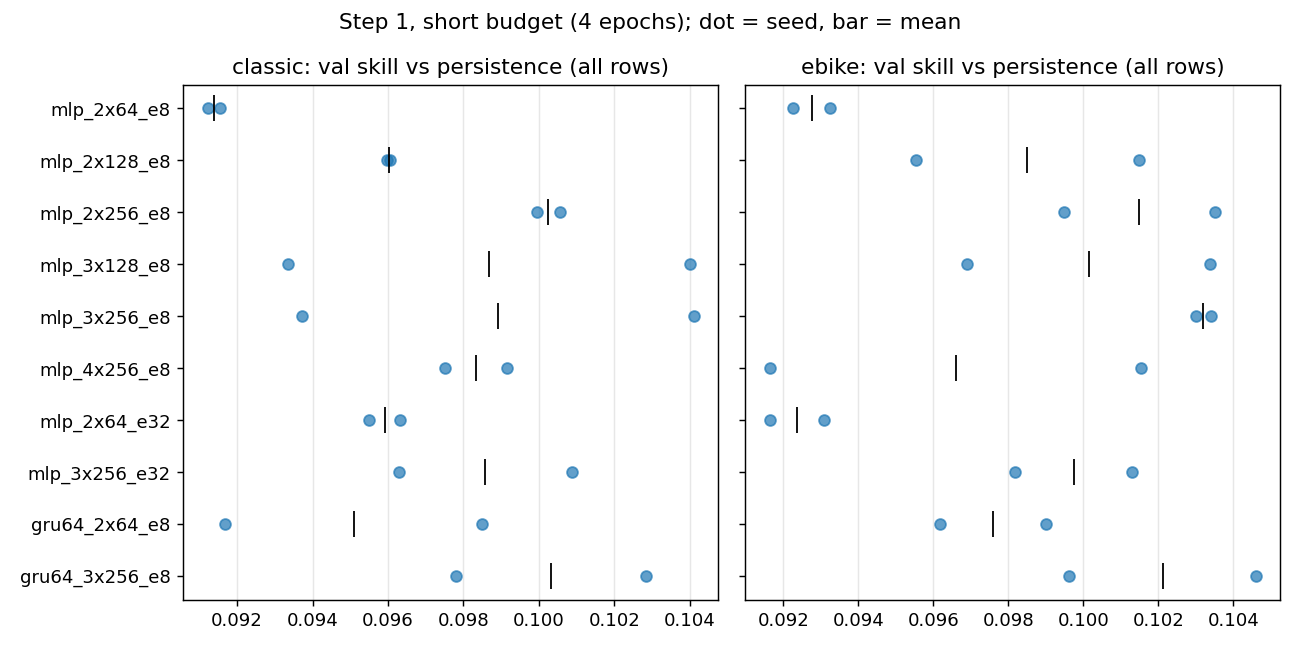

In [21]:
print("Fig. 1, Step 1")
src(ROOT / "reports" / "figures" / "search_step1.png", "src/38_search_report.py")
display(Image(filename=str(ROOT / "reports" / "figures" / "search_step1.png"), width=900))

Fig. 2, Step 2
  source: reports/figures/search_step2.png
  script: src/38_search_report.py


  commit: 73eb094 2026-11-12


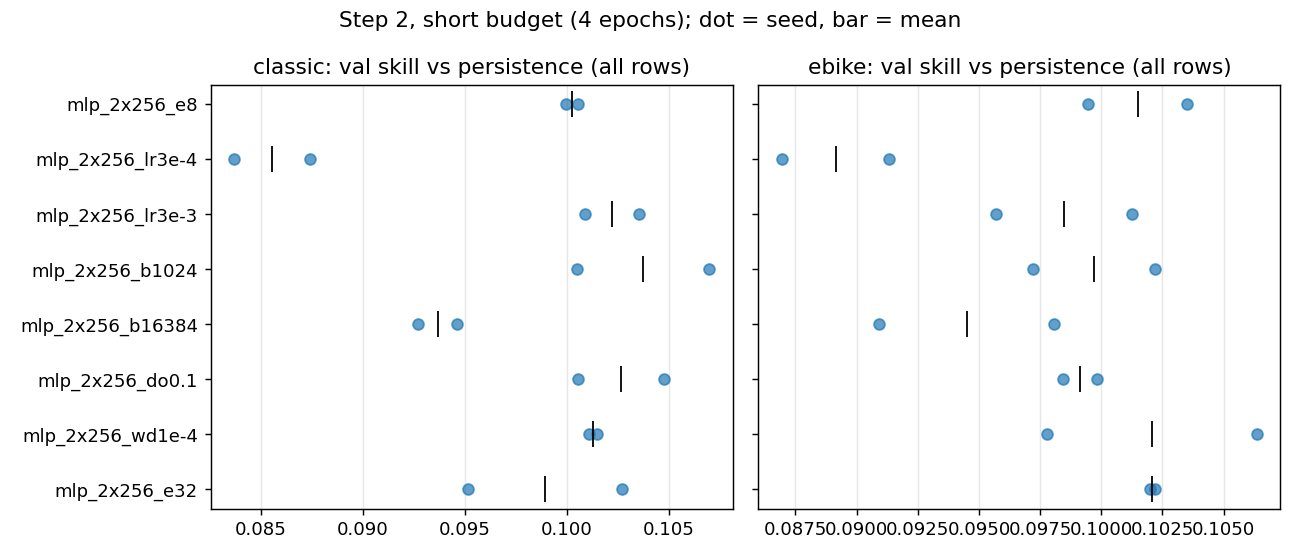

In [22]:
print("Fig. 2, Step 2")
src(ROOT / "reports" / "figures" / "search_step2.png", "src/38_search_report.py")
display(Image(filename=str(ROOT / "reports" / "figures" / "search_step2.png"), width=900))

Fig. 3, curves
  source: reports/figures/search_curves.png
  script: src/38_search_report.py


  commit: 73eb094 2026-11-12


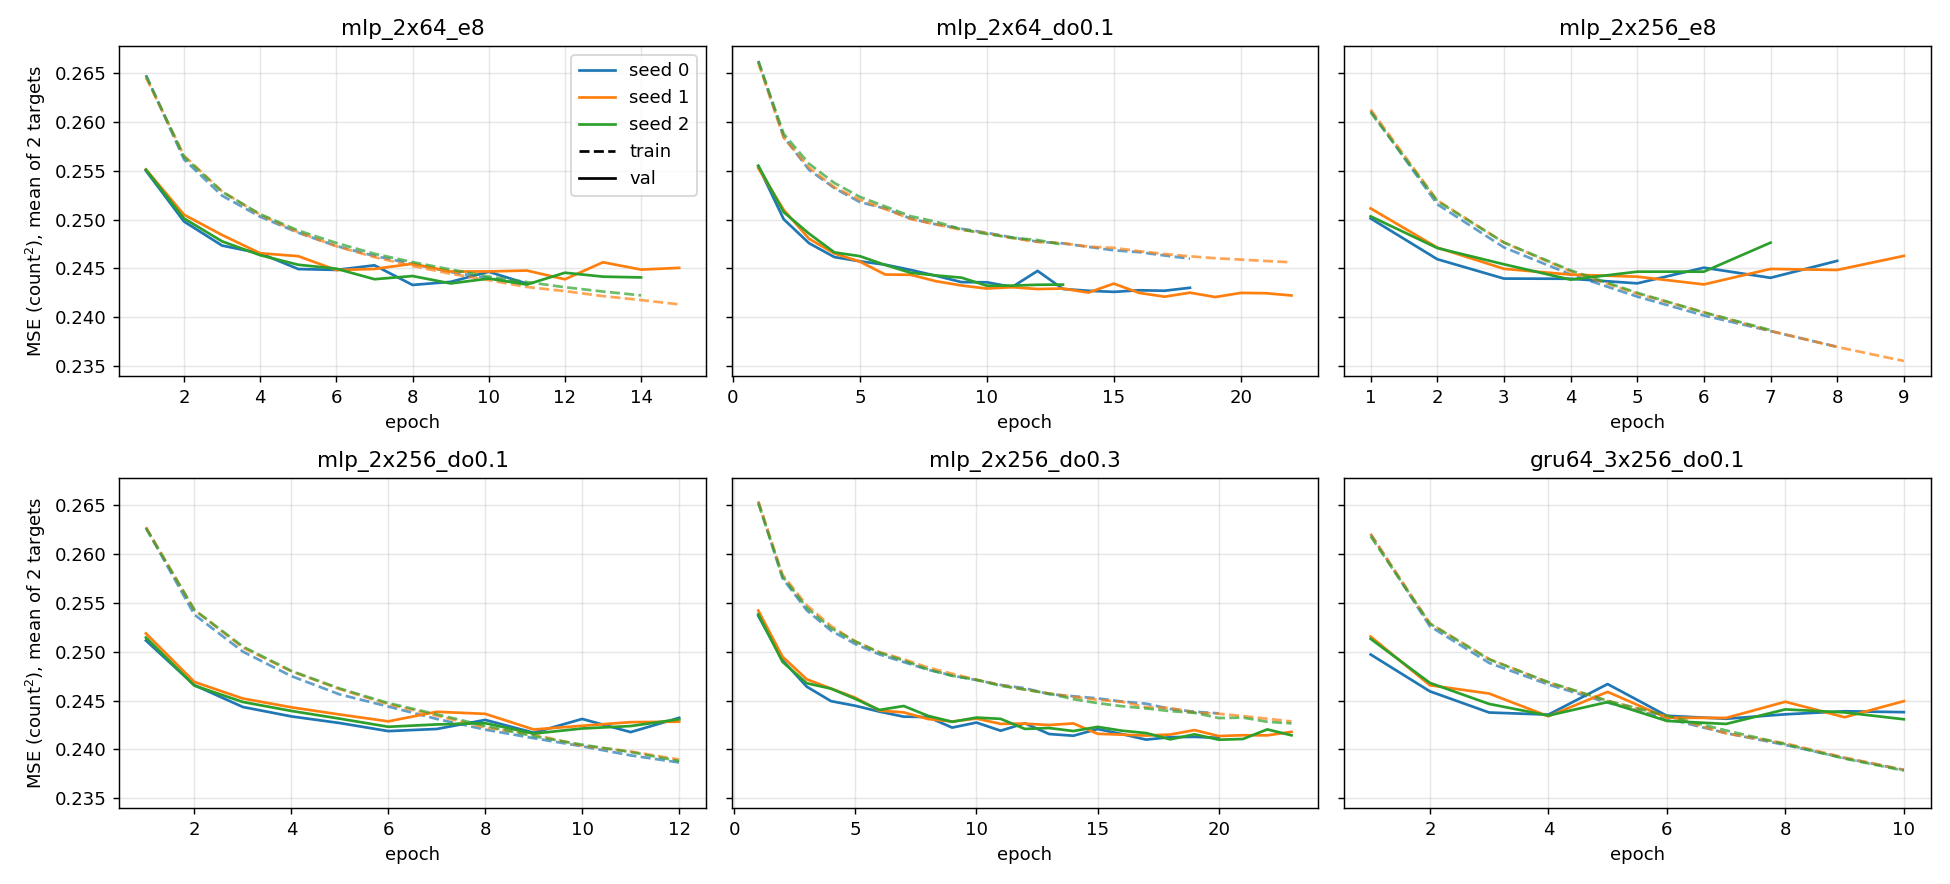

In [23]:
print("Fig. 3, curves")
src(ROOT / "reports" / "figures" / "search_curves.png", "src/38_search_report.py")
display(Image(filename=str(ROOT / "reports" / "figures" / "search_curves.png"), width=900))

Fig. 4, by horizon
  source: reports/figures/search_skill_by_horizon.png
  script: src/38_search_report.py


  commit: 73eb094 2026-11-12


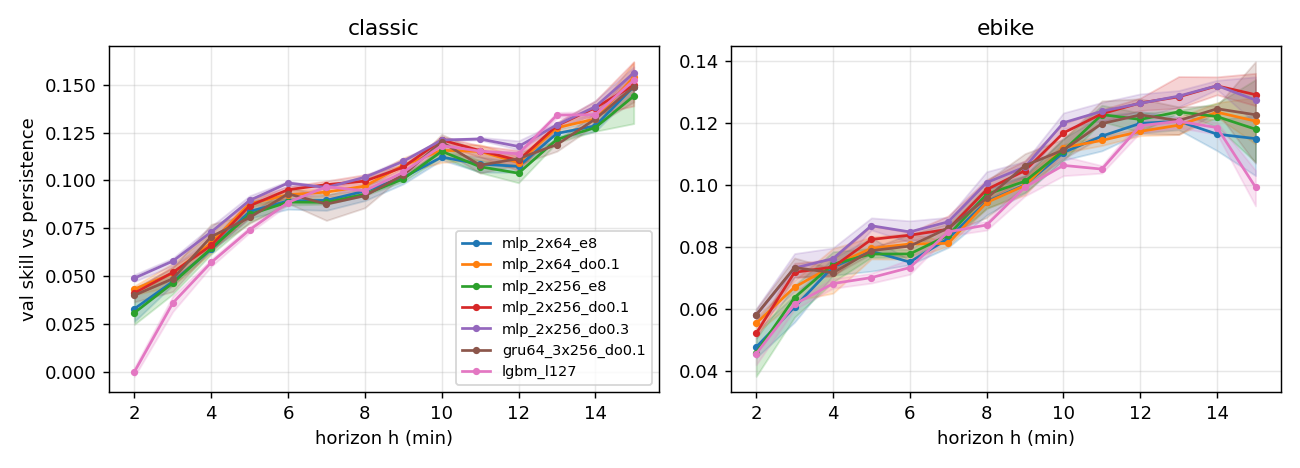

In [24]:
print("Fig. 4, by horizon")
src(ROOT / "reports" / "figures" / "search_skill_by_horizon.png", "src/38_search_report.py")
display(Image(filename=str(ROOT / "reports" / "figures" / "search_skill_by_horizon.png"), width=900))

Meeting (a)
  source: reports/figures/meeting_a_candidates.png
  script: src/40_meeting_figures.py


  commit: 73eb094 2026-11-12


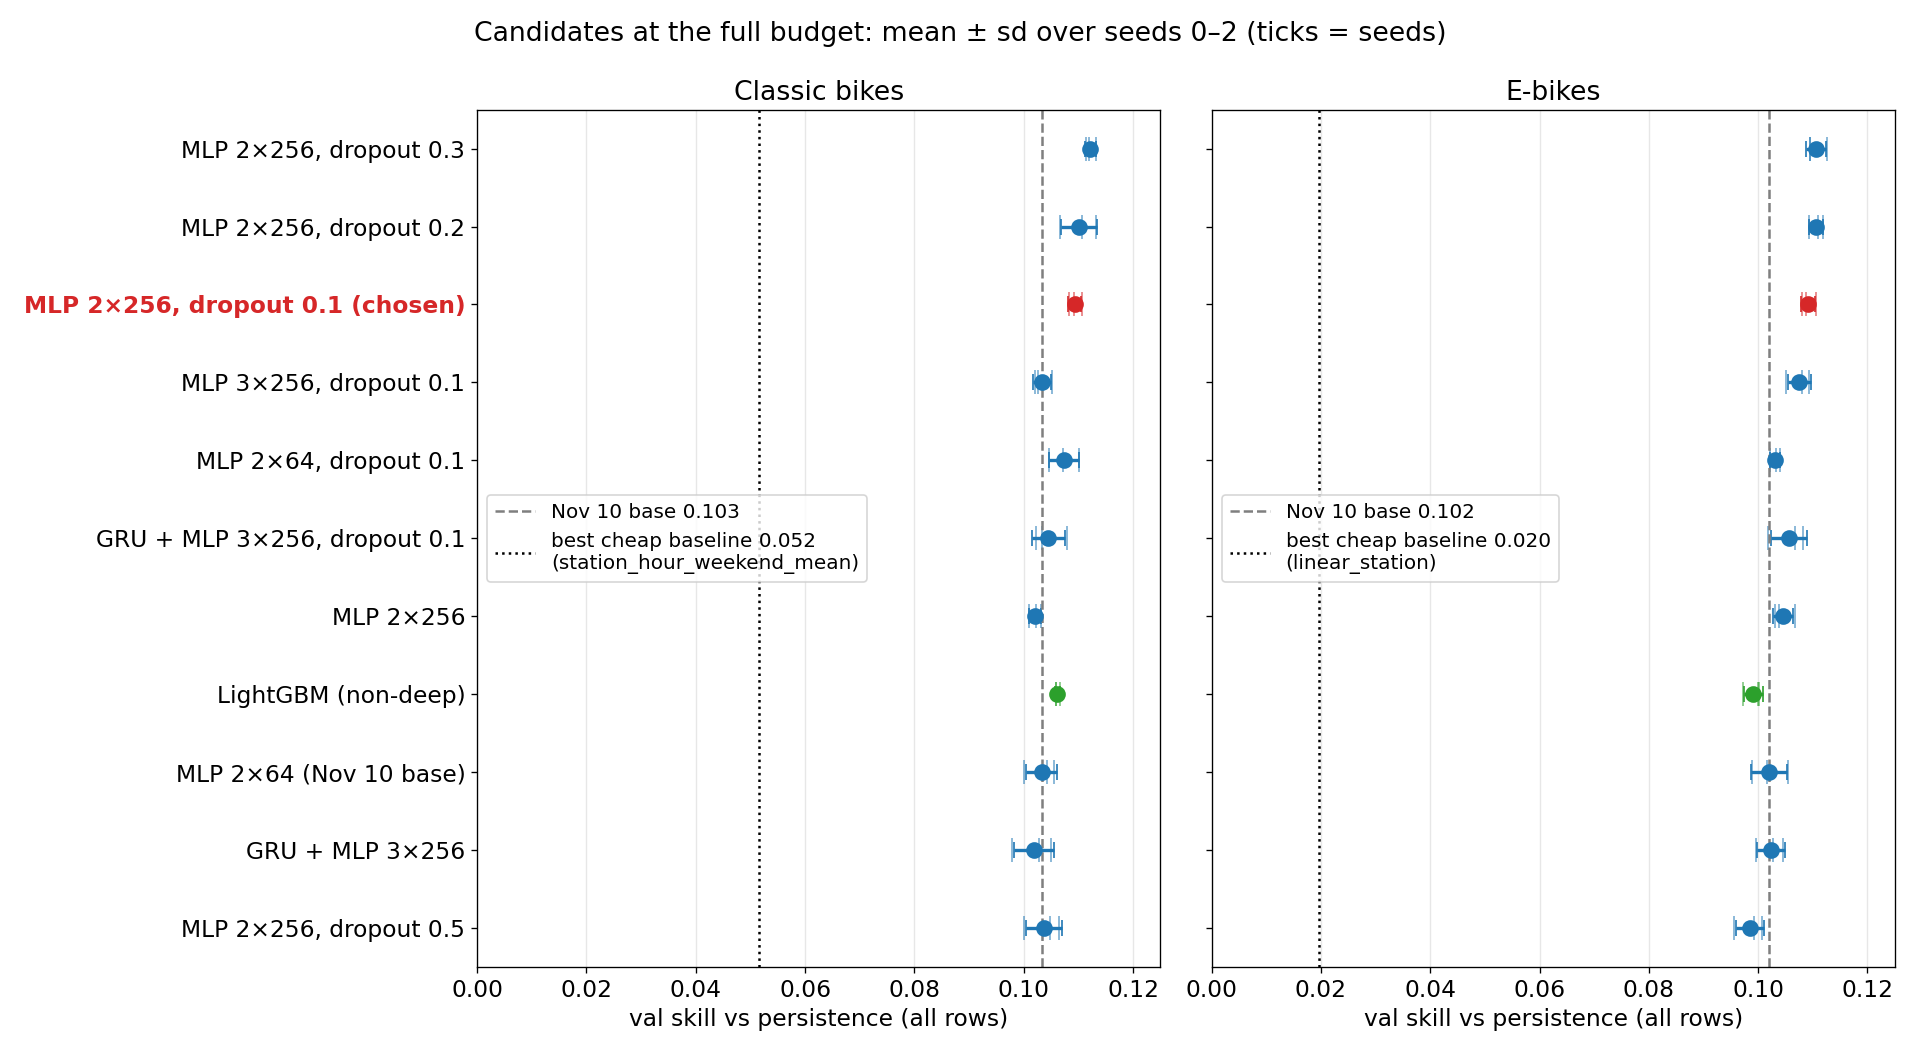

In [25]:
print("Meeting (a)")
src(ROOT / "reports" / "figures" / "meeting_a_candidates.png", "src/40_meeting_figures.py")
display(Image(filename=str(ROOT / "reports" / "figures" / "meeting_a_candidates.png"), width=900))

Meeting (b)
  source: reports/figures/meeting_b_curves.png
  script: src/40_meeting_figures.py


  commit: 73eb094 2026-11-12


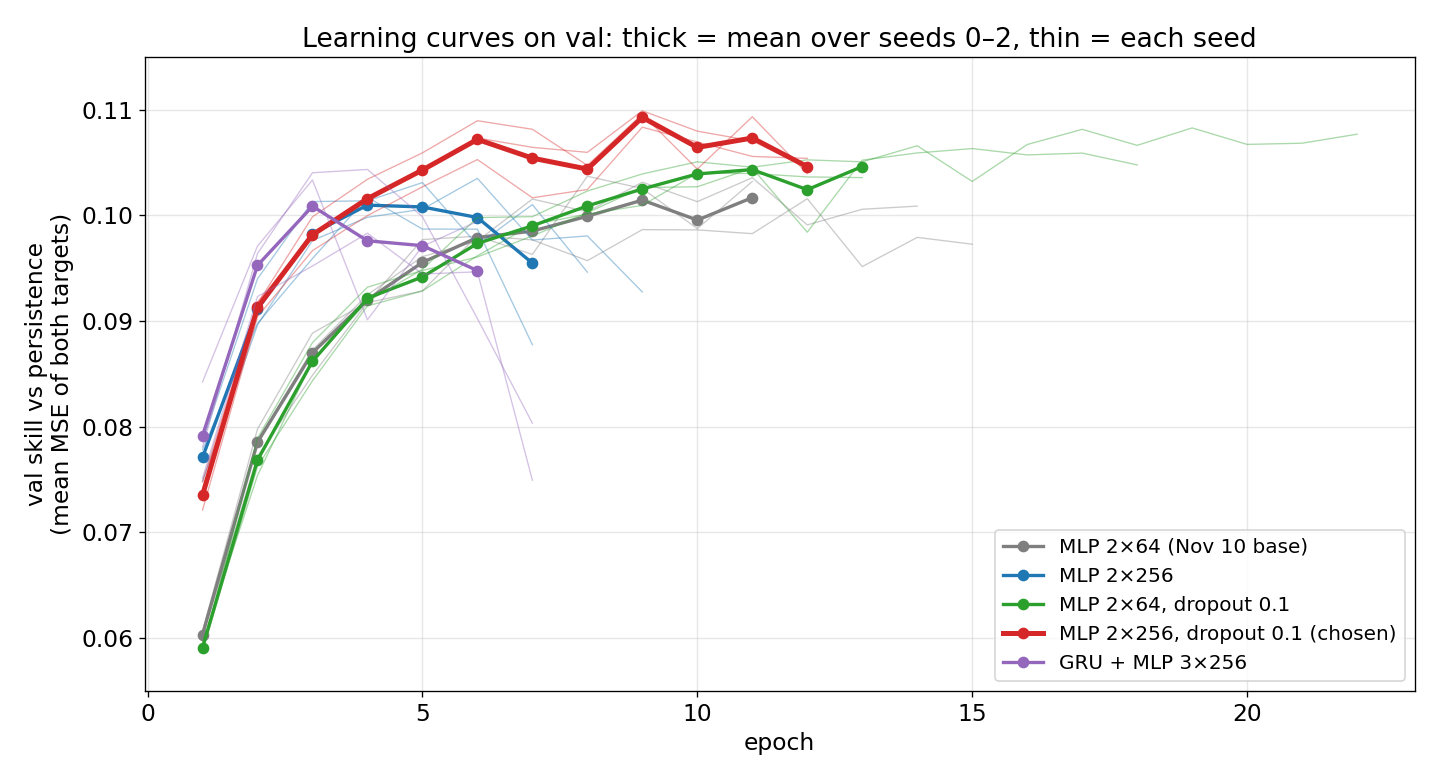

In [26]:
print("Meeting (b)")
src(ROOT / "reports" / "figures" / "meeting_b_curves.png", "src/40_meeting_figures.py")
display(Image(filename=str(ROOT / "reports" / "figures" / "meeting_b_curves.png"), width=900))

Meeting (c)
  source: reports/figures/meeting_c_horizon.png
  script: src/40_meeting_figures.py


  commit: 73eb094 2026-11-12


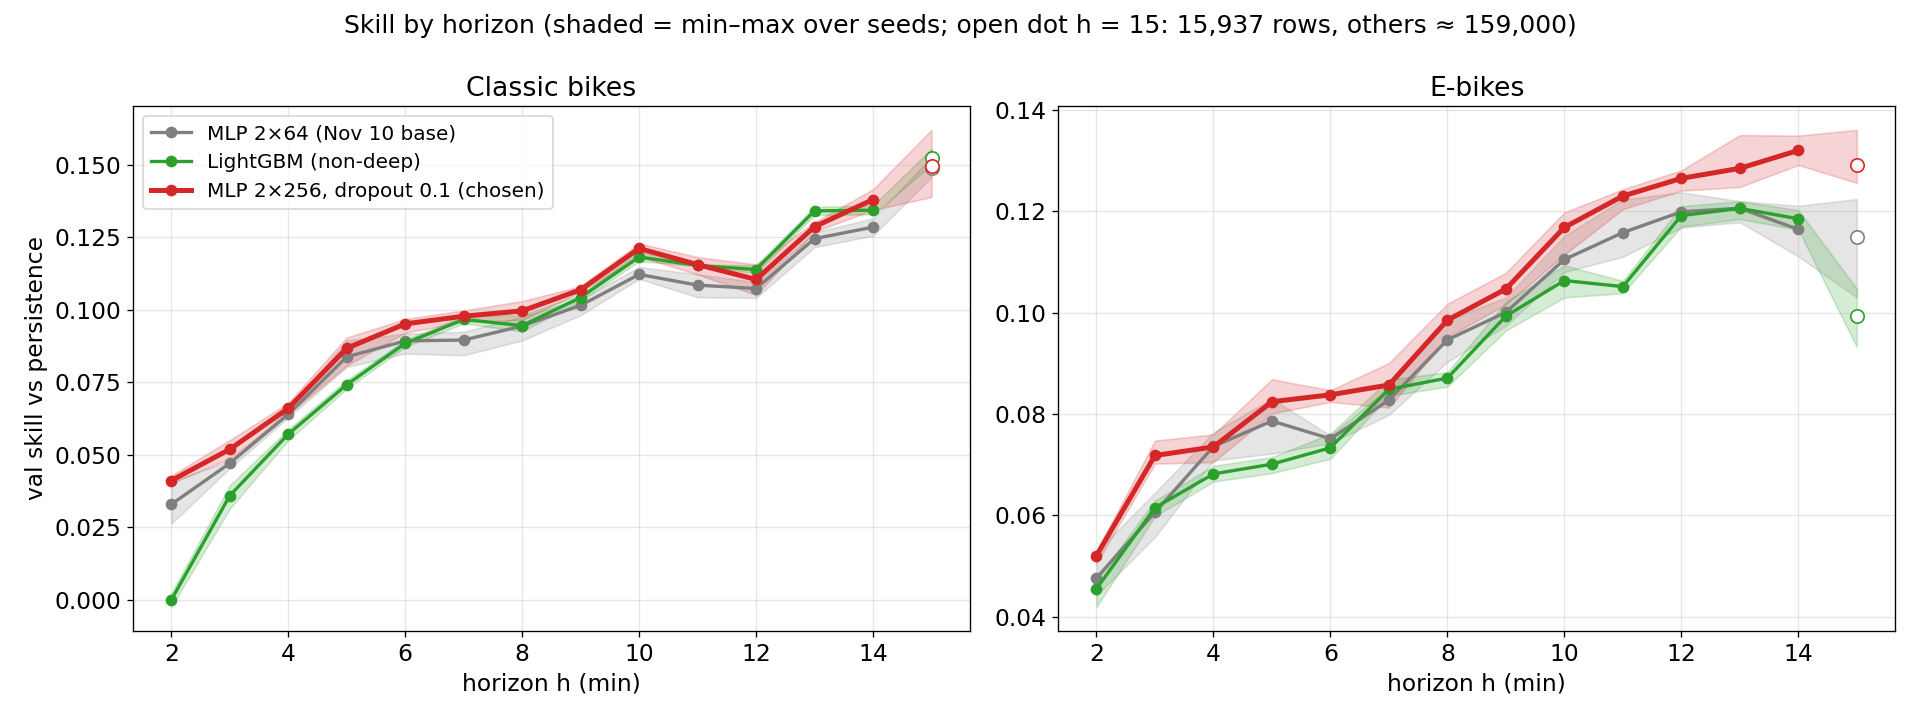

In [27]:
print("Meeting (c)")
src(ROOT / "reports" / "figures" / "meeting_c_horizon.png", "src/40_meeting_figures.py")
display(Image(filename=str(ROOT / "reports" / "figures" / "meeting_c_horizon.png"), width=900))

Meeting (d)
  source: reports/figures/meeting_d_low_rows.png
  script: src/40_meeting_figures.py
  commit: 73eb094 2026-11-12


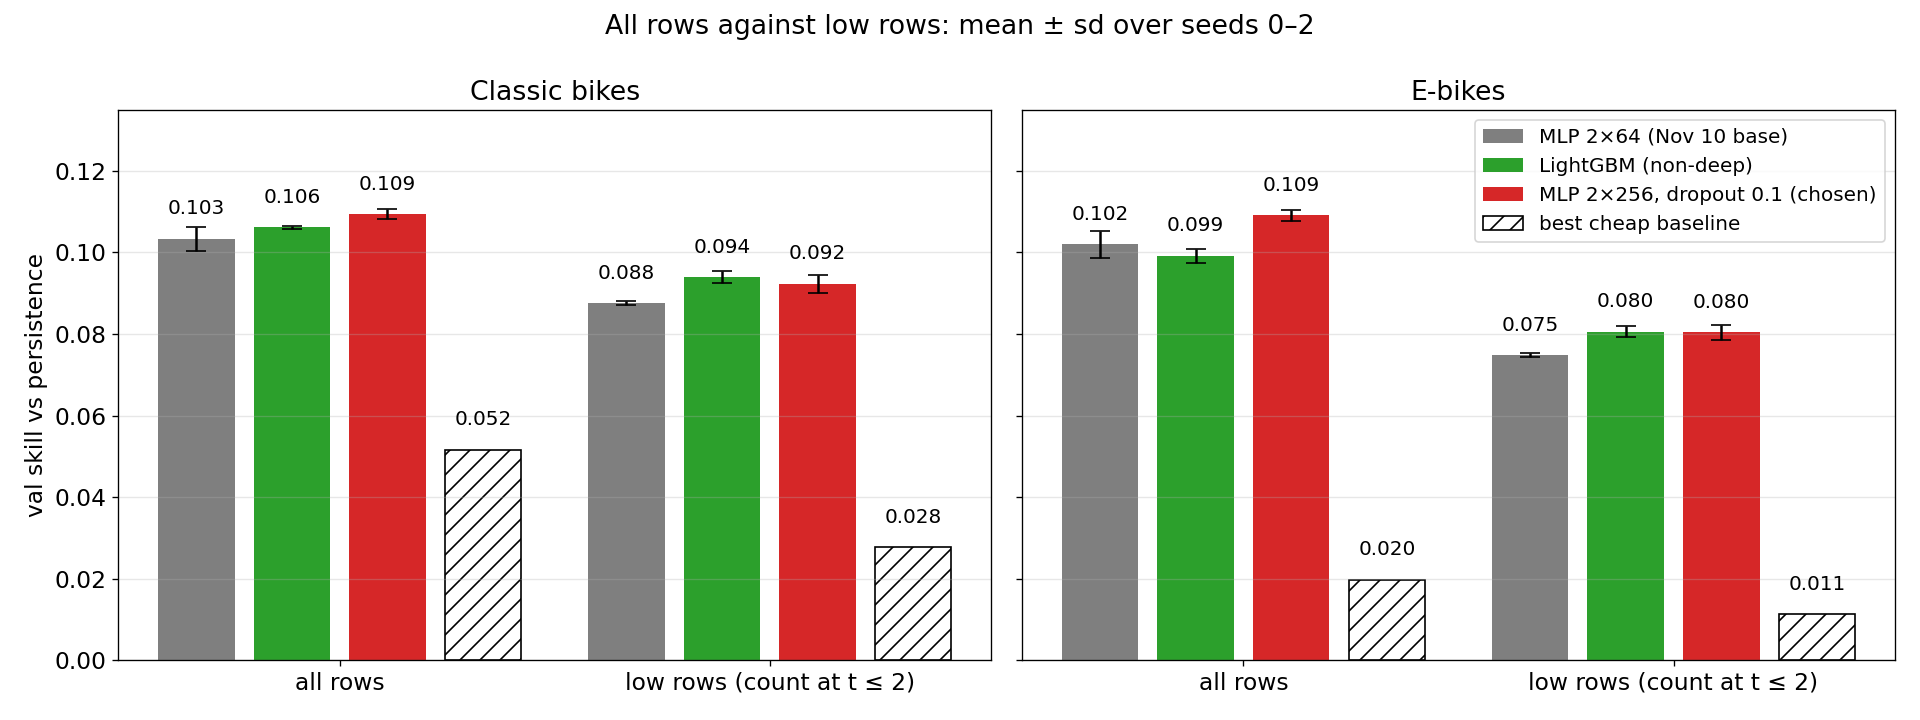

In [28]:
print("Meeting (d)")
src(ROOT / "reports" / "figures" / "meeting_d_low_rows.png", "src/40_meeting_figures.py")
display(Image(filename=str(ROOT / "reports" / "figures" / "meeting_d_low_rows.png"), width=900))